# 01 · What the FlyWire graph looks like

Week 1 exploration of the cleaned release-783 graph built by `make data`: who the neurons are, how
long the label tail is, how wiring is distributed, and one question that shapes the modelling:
**do same-type neurons connect to each other, or just to the same kinds of partners?**

Everything here reads `data/processed/`. Labels are used freely in this notebook because it
describes the data; no model sees them except as seeds and targets.

In [1]:
import duckdb, numpy as np, pandas as pd, scipy.sparse as sp, matplotlib.pyplot as plt
from flyct import config
from flyct.plotting import use_style, hbar, finish, SERIES, TEXT_SECONDARY

use_style()
FIG = config.ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
P = config.PROCESSED
feats = pd.read_parquet(P / "features.parquet")
labels = pd.read_parquet(P / "labels.parquet")
edges = pd.read_parquet(P / "edges.parquet", columns=["pre_root_id", "post_root_id", "syn_count"])
print(f"{len(feats):,} neurons · {len(edges):,} edges (≥{config.SYNAPSE_THRESHOLD} synapses) · "
      f"{edges.syn_count.sum():,} synapses in kept edges · {feats.shape[1] - 1} features")

139,255 neurons · 2,700,513 edges (≥5 synapses) · 34,153,566 synapses in kept edges · 176 features


## 1 · Neurons per super class

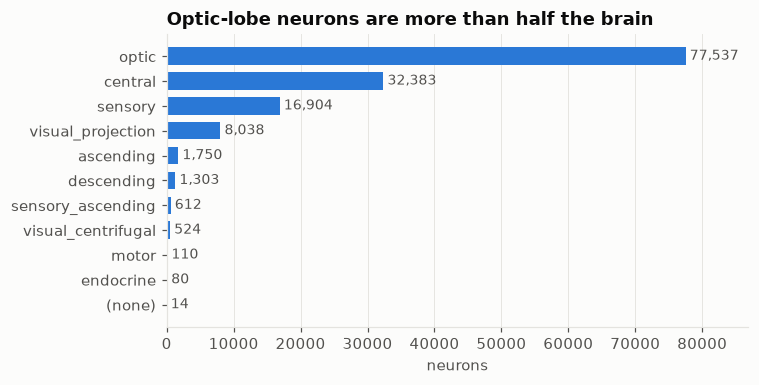

,share
super_class,
optic,0.557
central,0.233
sensory,0.121
visual_projection,0.058
ascending,0.013
descending,0.009
sensory_ascending,0.004
visual_centrifugal,0.004
motor,0.001


In [2]:
sc = labels.super_class.fillna("(none)").value_counts()
fig, ax = plt.subplots(figsize=(7, 3.6))
hbar(ax, sc.index.tolist(), sc.values)
ax.set_title("Optic-lobe neurons are more than half the brain")
ax.set_xlabel("neurons")
finish(fig, FIG / "super_class_counts.png")
(sc / sc.sum()).round(3).to_frame("share")

## 2 · How many neurons lack a label at each level

Missing labels shrink the usable set for each task. They also matter for evaluation: a neuron without
a type can't be a seed or a test case for the cell-type task.

In [3]:
cov = labels.assign(super_class=labels.super_class.fillna("(none)")).groupby("super_class").agg(
    neurons=("root_id", "size"),
    no_class=("cell_class", lambda s: s.isna().sum()),
    no_type=("cell_type", lambda s: s.isna().sum()),
).sort_values("neurons", ascending=False)
cov.loc["total"] = cov.sum()
cov

,neurons,no_class,no_type
super_class,,,
optic,77537,6,616
central,32383,21963,143
sensory,16904,2,308
visual_projection,8038,7949,28
ascending,1750,0,141
descending,1303,1301,0
sensory_ascending,612,0,285
visual_centrifugal,524,499,6
motor,110,4,0


## 3 · The long tail of cell types

Most types have only a few neurons. Two consequences for the plan:
- **Singleton types** (one neuron) can never be both a seed and a test case, so they drop out of
  cell-type evaluation whenever we guarantee one seed per type.
- Accuracy alone will be dominated by the big types; that's why the plan reports macro F1 and accuracy by type size.

In [4]:
sizes = labels.cell_type.dropna().value_counts()
buckets = pd.cut(sizes, [0, 1, 2, 10, 100, np.inf], labels=["1", "2", "3–10", "11–100", ">100"])
tail = pd.DataFrame({"types": sizes.groupby(buckets, observed=False).size(),
                     "neurons": sizes.groupby(buckets, observed=False).sum()})
tail["share_of_types"] = (tail.types / tail.types.sum()).round(3)
tail["share_of_neurons"] = (tail.neurons / tail.neurons.sum()).round(3)
tail.index.name = "neurons per type"
print(f"{len(sizes):,} cell types; median size {sizes.median():.0f}; largest {sizes.index[0]} ({sizes.iloc[0]:,})")
tail

8,840 cell types; median size 2; largest R1-6 (8,452)


,types,neurons,share_of_types,share_of_neurons
neurons per type,,,,
1,120,120,0.014,0.001
2,4513,9026,0.511,0.066
3–10,3518,17385,0.398,0.126
11–100,539,15709,0.061,0.114
>100,150,95474,0.017,0.693


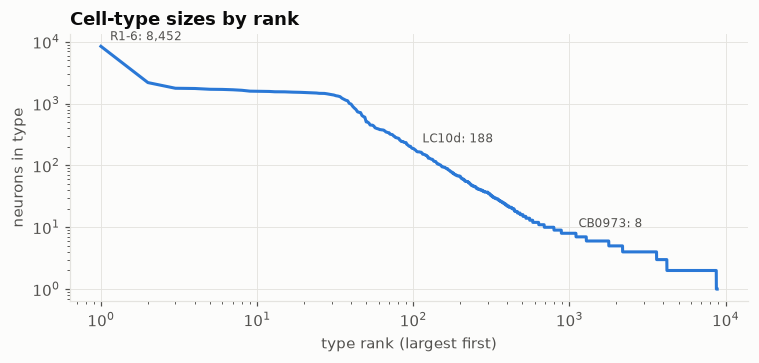

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.4))
rank = np.arange(1, len(sizes) + 1)
ax.loglog(rank, sizes.values, color=SERIES[0])
ax.set_title("Cell-type sizes by rank")
ax.set_xlabel("type rank (largest first)"); ax.set_ylabel("neurons in type")
for r in (1, 100, 1000):
    ax.annotate(f"{sizes.index[r-1]}: {sizes.iloc[r-1]:,}", (r, sizes.iloc[r-1]),
                textcoords="offset points", xytext=(6, 4), fontsize=8, color=TEXT_SECONDARY)
finish(fig, FIG / "type_size_rank.png")

## 4 · Degree distributions

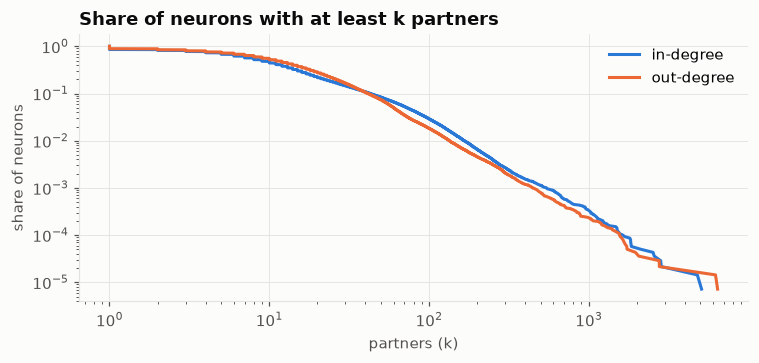

,in_degree,out_degree,in_syn,out_syn
count,139255.0,139255.0,139255.0,139255.0
mean,19.4,19.4,245.3,245.3
std,49.4,45.6,802.9,733.2
min,0.0,0.0,0.0,0.0
50%,9.0,11.0,92.0,105.0
90%,43.0,42.0,480.6,517.0
99%,166.0,134.0,2716.3,2363.0
max,5080.0,6399.0,67616.0,92957.0


In [6]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for col, name, color in [("in_degree", "in-degree", SERIES[0]), ("out_degree", "out-degree", SERIES[1])]:
    d = np.sort(feats[col].values)
    ccdf = 1 - np.arange(len(d)) / len(d)
    ax.loglog(np.maximum(d, 1), ccdf, color=color, label=name)
ax.set_title("Share of neurons with at least k partners")
ax.set_xlabel("partners (k)"); ax.set_ylabel("share of neurons")
ax.legend()
finish(fig, FIG / "degree_ccdf.png")
feats[["in_degree", "out_degree", "in_syn", "out_syn"]].describe(percentiles=[.5, .9, .99]).round(1)

In [7]:
isolated = ((feats.in_degree == 0) & (feats.out_degree == 0)).sum()
print(f"neurons with no partner at ≥{config.SYNAPSE_THRESHOLD} synapses: {isolated:,}")
print(f"no inputs: {(feats.in_degree == 0).sum():,} · no outputs: {(feats.out_degree == 0).sum():,}")
print("\nno-input neurons by super class:")
print(labels.loc[feats.in_degree.values == 0, "super_class"].value_counts().head(6).to_string())

neurons with no partner at ≥5 synapses: 5,074
no inputs: 14,063 · no outputs: 9,904

no-input neurons by super class:
super_class
sensory              10973
optic                 1425
ascending              762
central                394
sensory_ascending      380
visual_projection       50


## 5 · Reciprocal connections

In [8]:
con = duckdb.connect()
recip = con.sql("""
    SELECT count(*) FILTER (WHERE r.pre_root_id IS NOT NULL) * 1.0 / count(*) AS share
    FROM edges e LEFT JOIN edges r ON e.pre_root_id = r.post_root_id AND e.post_root_id = r.pre_root_id
""").fetchone()[0]
n = len(feats); density = len(edges) / (n * (n - 1))
print(f"{recip:.1%} of edges have a reverse edge; a random graph of this density would give {density:.4%}")

14.0% of edges have a reverse edge; a random graph of this density would give 0.0139%


## 6 · Same type: linked to each other, or linked to the same kinds of partners?

This decides how much a graph neural network can help. Message passing averages a neuron's neighbours,
which works best when neighbours share the neuron's label (*homophily*). NTAC's features instead
describe *which types* a neuron connects to, which works even when same-type neurons never touch.

Two measurements:
1. **Edge homophily**: the share of edges joining two neurons of the same type, against what random
   wiring with the same type frequencies would give.
2. **Partner-profile similarity**: cosine similarity of two neurons' synapse counts to and from each
   partner type, for same-type pairs against different-type pairs in the same super class.

In [9]:
idx = pd.Series(np.arange(n), index=feats.root_id.values)
src, dst = idx[edges.pre_root_id].values, idx[edges.post_root_id].values
lab = labels.set_index("root_id").loc[feats.root_id]

def homophily(level):
    y = lab[level].values
    ok = pd.notna(y[src]) & pd.notna(y[dst])
    same = (y[src][ok] == y[dst][ok]).mean()
    p_out = pd.Series(y[src][ok]).value_counts(normalize=True)
    p_in = pd.Series(y[dst][ok]).value_counts(normalize=True)
    expected = (p_out * p_in.reindex(p_out.index, fill_value=0)).sum()
    return same, expected, ok.mean()

rows = []
for level in ["super_class", "cell_class", "cell_type"]:
    same, exp, cov_ = homophily(level)
    rows.append({"label": level, "same-label edges": same, "random expectation": exp,
                 "lift": same / exp, "edges with both labelled": cov_})
pd.DataFrame(rows).set_index("label").round(3)

,same-label edges,random expectation,lift,edges with both labelled
label,,,,
super_class,0.729,0.362,2.016,1.000
cell_class,0.255,0.131,1.949,0.492
cell_type,0.011,0.003,4.337,0.995


In [10]:
# Same measurement for cell type, split by the source neuron's super class.
y = lab.cell_type.values; s = lab.super_class.values
ok = pd.notna(y[src]) & pd.notna(y[dst])
by = pd.DataFrame({"sc": s[src][ok], "same": y[src][ok] == y[dst][ok]}).groupby("sc").same.agg(["mean", "size"])
by.columns = ["same-type edge share", "edges"]
by.sort_values("edges", ascending=False).round(3)

,same-type edge share,edges
sc,,
optic,0.008,1321018
central,0.016,962061
visual_projection,0.018,189539
visual_centrifugal,0.001,68391
sensory,0.012,58313
ascending,0.001,55263
descending,0.006,30917
sensory_ascending,0.028,2284
motor,0.034,387


In [11]:
# Partner-type profiles: synapses from each neuron to each partner type (out) and from each type (in).
typed = lab.cell_type.notna().values
codes, uniq = pd.factorize(lab.cell_type)
T = sp.csr_matrix((np.ones(typed.sum()), (np.flatnonzero(typed), codes[typed])), shape=(n, len(uniq)))
A = sp.csr_matrix((edges.syn_count.values.astype(np.float32), (src, dst)), shape=(n, n))
profile = sp.hstack([A @ T, A.T @ T]).tocsr()
norms = np.sqrt(profile.multiply(profile).sum(axis=1)).A1
norms[norms == 0] = 1
profile = sp.diags(1 / norms) @ profile

rng = np.random.default_rng(0)
def cosine(i, j):
    return np.asarray(profile[i].multiply(profile[j]).sum(axis=1)).ravel()

# Same-type pairs: two random neurons from the same type (types with >= 2 neurons).
lab_typed = pd.DataFrame({"i": np.flatnonzero(typed), "t": codes[typed], "sc": s[typed]})
groups = lab_typed.groupby("t").i.apply(np.array)
groups = groups[groups.map(len) >= 2]
pick = rng.choice(len(groups), 20_000)
pairs_same = np.array([rng.choice(groups.iloc[k], 2, replace=False) for k in pick])
# Different-type pairs within the same super class.
pairs_diff = []
for sc_name, g in lab_typed.groupby("sc"):
    m = int(20_000 * len(g) / len(lab_typed))
    a, b = rng.choice(g.i.values, m), rng.choice(g.i.values, m)
    keep = codes[a] != codes[b]
    pairs_diff.append(np.c_[a[keep], b[keep]])
pairs_diff = np.vstack(pairs_diff)

cos_same, cos_diff = cosine(*pairs_same.T), cosine(*pairs_diff.T)
direct_same = np.asarray((A[pairs_same[:, 0], pairs_same[:, 1]] + A[pairs_same[:, 1], pairs_same[:, 0]]) > 0).ravel().mean()
direct_diff = np.asarray((A[pairs_diff[:, 0], pairs_diff[:, 1]] + A[pairs_diff[:, 1], pairs_diff[:, 0]]) > 0).ravel().mean()
pd.DataFrame({
    "median partner-profile cosine": [np.median(cos_same), np.median(cos_diff)],
    "mean partner-profile cosine": [cos_same.mean(), cos_diff.mean()],
    "share directly connected": [direct_same, direct_diff],
}, index=["same type", "different type, same super class"]).round(3)

,median partner-profile cosine,mean partner-profile cosine,share directly connected
same type,0.86,0.782,0.100
"different type, same super class",0.00,0.044,0.001


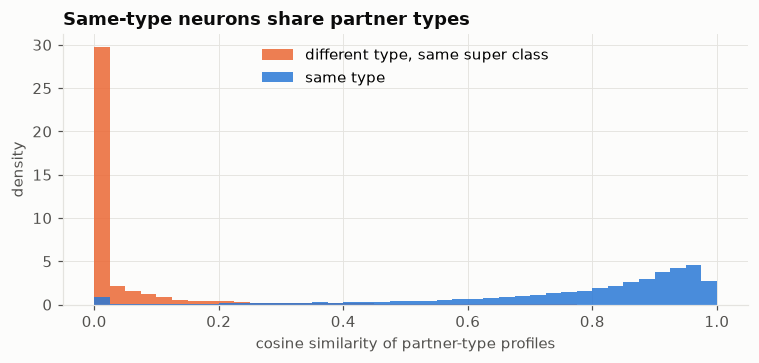

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(0, 1, 41)
ax.hist(cos_diff, bins=bins, color=SERIES[1], alpha=0.85, density=True, label="different type, same super class")
ax.hist(cos_same, bins=bins, color=SERIES[0], alpha=0.85, density=True, label="same type")
ax.set_title("Same-type neurons share partner types")
ax.set_xlabel("cosine similarity of partner-type profiles"); ax.set_ylabel("density")
ax.legend(loc="upper center")
finish(fig, FIG / "partner_profile_similarity.png")

### What this means for Weeks 2–3

**Same-type neurons connect to the same *kinds* of partners, not to each other.** Only 1.1% of edges join
two neurons of the same type (4.3× random, but small in absolute terms), and only 10% of same-type pairs
are directly connected. Yet their partner-type profiles are nearly identical: median cosine 0.86, against
0.00 for different types in the same super class.

- **NTAC is a strong baseline, as expected.** Its features are exactly these partner-type profiles.
- **A GNN that averages raw neighbour features won't see type identity.** It needs the *types* of its
  neighbours, so the "seed labels as input" trick is essential, not optional. One aggregation over
  seed-label embeddings is essentially a learned partner-type profile.
- **Caveat:** this uses every label, and optic-lobe types were partly defined by connectivity, so part of
  this similarity is built in. That's another reason to report regions separately.

**Other facts the plan has to absorb**

- **Class labels are missing for 68% of central-brain neurons** (21,963 of 32,383) and almost all
  visual-projection and descending neurons. The class-level task is mostly an optic and sensory problem;
  report its coverage next to every class result.
- **The type tail is extreme.** 51% of the 8,840 types have exactly 2 neurons (typically one per side), and
  the 150 types with more than 100 neurons hold 69% of all neurons. Accuracy will mostly measure big optic
  types, so macro F1 and accuracy by type size are required. The 120 singleton types can never be tested.
- **5,074 neurons have no partner at ≥ 5 synapses**, mostly sensory neurons with no inputs. Connectivity-only
  methods can't type them at all, which is a concrete case for the neuropil and neurotransmitter features
  (the open question).
- **Reciprocity is 14%**, about 1,000× what random wiring of this density would give.
- **Hemisphere transfer needs mirrored features.** Neuropil columns carry `_L`/`_R`, so a model trained on one
  side sees different columns on the other. Week 2 will map them to "same side / other side" first.